[*********************100%***********************]  1 of 1 completed


Price    Returns        RSI      MACD       ATR  Volatility   Momentum
Regime                                                                
0      -0.003837  40.924029 -2.941483  5.901450    0.015515  -8.965205
1       0.002653  63.701730  4.402268  5.264967    0.009173  10.111487
2       0.001146  58.261511  0.944398  1.759555    0.007285   1.332094


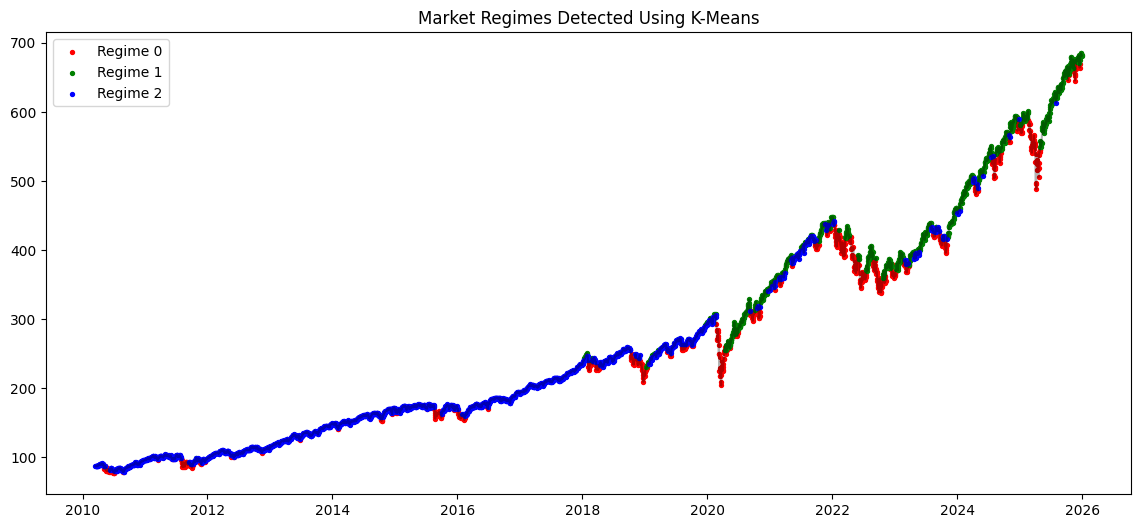

Accuracy: 0.9459119496855346


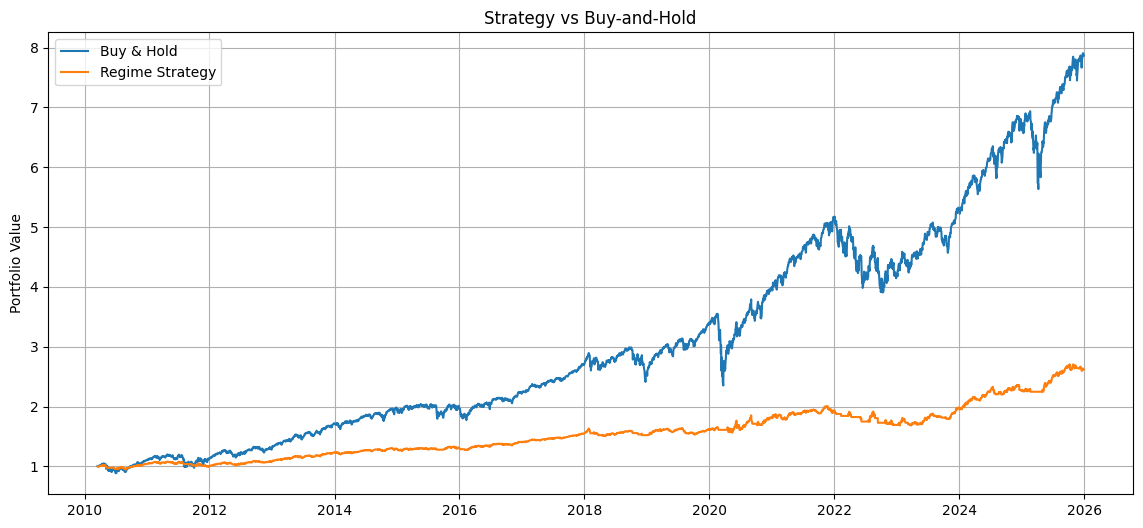

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ticker = "SPY"
start = "2010-01-01"
end = "2025-12-31"



df = yf.download(
    ticker,
    start,
    end,
    interval = "1d",
    auto_adjust = True,
)

# We convert our data into series as ta library only takes series data but our database is data frame
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

## Returns
df["Returns"] = df["Close"].pct_change()
df = df.dropna()


## SMA
df["SMA20"] = df["Close"].rolling(20).mean()
df["SMA50"] = df["Close"].rolling(50).mean()

## EMA
df["EMA20"] = df["Close"].ewm(span=20).mean()           ## This makes weighted closes and the mean makes it moving average
df["EMA50"] = df["Close"].ewm(span=50).mean()

## Momentum
df["Momentum"] = df["Close"] - df["Close"].shift(10)    ## This calculates momentum that is how much movements were made in last 10 days

## Volatility
df["Volatility"] = df["Returns"].rolling(20).std()      ## This calculates the volatility

## RSI
from ta.momentum import RSIIndicator
rsi = RSIIndicator(
    close = df["Close"],
    window = 14
)
df["RSI"] = rsi.rsi()

## MACD
from ta.trend import MACD
macd = MACD(df['Close'])
df["MACD"] = macd.macd()
df["MACD Signal"] = macd.macd_signal()
df["MSCD Hist"] = macd.macd_diff()

## ATR
from ta.volatility import AverageTrueRange
atr = AverageTrueRange(
    high = df["High"],
    low = df["Low"],
    close = df["Close"]
)
df["ATR"] = atr.average_true_range()

## Bollinger Band
from ta.volatility import BollingerBands

bb = BollingerBands(df["Close"])
df["BB High"] = bb.bollinger_hband()
df["BB Low"] = bb.bollinger_lband()
df["BB Mid"] = bb.bollinger_mavg()

df = df.dropna()


corr_matrix = df.corr(numeric_only=True)

features = [
    "Returns",
    "RSI",
    "MACD",
    "ATR",
    "Volatility",
    "Momentum"
]


x = df[features]

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
pca = PCA(n_components=4)
x_pca = pca.fit_transform(x_scaled)

from sklearn.cluster import KMeans
model = KMeans(
    random_state = 42,
    n_clusters = 3,
    n_init = 20
)

df["Regime"] = model.fit_predict(x_pca)

regime_summary = df.groupby("Regime")[features].mean()
print(regime_summary)

plt.figure(figsize=(14,6))

for regime, color in colors.items():
    mask = df["Regime"] == regime
    plt.scatter(
        df.index[mask],
        df["Close"][mask],
        color=color,
        s=8,
        label=f"Regime {regime}"
    )

plt.plot(df.index, df["Close"], color="black", alpha=0.3)

plt.legend()
plt.title("Market Regimes Detected Using K-Means")
plt.show()


x = df[features]
y = df["Regime"]

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.2,
    random_state = 42,
    shuffle = False
)

from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
    n_estimators = 100,
    random_state = 42
  )
rf.fit(x_train, y_train)

y_pred = rf.predict(x_test)

from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
#print("Confusion Matrix:\n", cm)


importance = pd.Series(
    rf.feature_importances_,
    index = features
)

importance = importance.sort_values(ascending=False)

### Investing Hypothesis

position_map = {
    0 : 0.0,   # Bear
    1 : 1.0,   # Bull
    2 : 0.5    # Consolidated
  }

# This allows us to add strategy to each regime
df["Position"] = df["Regime"].map(position_map)

# This calculates returns based on how much we are invested in spy
df["Strategy Returns"] = (df["Position"].shift(1)*df["Returns"])

# Cumulative REturn
df["BuyHold"] = (1+df["Returns"]).cumprod()    # Calculates compounded returns

df["Strategy"] = (1+df["Strategy Returns"]).cumprod()

# plotting the returns of both strategy
plt.figure(figsize=(14,6))

plt.plot(df.index, df["BuyHold"], label="Buy & Hold")

plt.plot(df.index, df["Strategy"], label="Regime Strategy")

plt.legend()

plt.title("Strategy vs Buy-and-Hold")

plt.ylabel("Portfolio Value")

plt.grid(True)

plt.show()